# SAP Inventory Data Cleaning & Analysis

## Project Overview

The goal of this project is to combine two inventory datasets, clean inconsistent and missing data, standardize data formats, and perform a basic analysis of inventory levels across two locations: Tallinn and Tartu.

## Project Objectives

### 1. Data Preparation and Cleaning
- Load and combine two inventory datasets into one table.
- Inspect the dataset structure and identify data quality issues.
- Remove duplicate records.
- Handle missing values in important columns.
- Standardize text values and capitalization.
- Remove leading and trailing spaces from text fields.
- Clean the `Stock_Qty` column by removing text such as `pcs` and converting values to numeric format.
- Standardize date formats in the `Posting_Date` column.
- Identify suspicious or inconsistent inventory records.

### 2. Inventory Analysis
- Identify the top 5 products by stock quantity.
- Calculate the total recorded stock quantity in Tallinn.
- Calculate the total recorded stock quantity in Tartu.
- Compare inventory levels between the two locations.
- Visualize stock distribution by location using charts.
- Identify products with missing, zero, or potentially abnormal stock quantities.

## Tools and Libraries

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

## Expected Outcome

A cleaned and standardized inventory dataset, supported by basic analysis and visualizations that help compare stock levels between Tallinn and Tartu.

### 1.Importing Libraries and Loading Data

Import the libraries required for data manipulation, cleaning, and visualization. Load two CSV files into `df1` and `df2` to demonstrate how multiple datasets can be combined into a single table.

In [31]:
import pandas as pd
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df1= pd.read_csv("../data/sap_export_plant1.csv")
df2= pd.read_csv("../data/sap_export_plant2.csv")



In [32]:
df2.columns = ['Material_ID', 'Category', 'Stock_Qty', 'Posting_Date', 'Plant_Location']
df = pd.concat([df1, df2], ignore_index=True)

df

,Material_ID,Category,Stock_Qty,Posting_Date,Plant_Location
0,SAP-1092,Finished Goods,NaN,2026-07-08,Tallinn Plant
1,SAP-1092,raw material,26,NaN,Tallinn Plant
2,SAP-8831,raw material,NaN,29-06-2026,Tallinn Plant
3,SAP-2204,Packaging,424,10-02-2026,Tallinn Plant
4,SAP-9941,Packaging,100 pcs,2026-04-08,Tallinn Plant
...,...,...,...,...,...
95,SAP-2204,PACKAGING,59,2026.04.21,Tartu Site
96,SAP-4051,Finished Goods,272,2026.06.16,Tartu Site
97,SAP-8831,Packaging,243,2026.04.22,Tartu Site
98,SAP-4051,raw material,49,13-03-2026,Tartu Site


### 2.Initial Data Quality Check

The `df.info()` method provides an overview of the dataset, including the number of rows, columns, non-null values, and data types.

The initial inspection shows several issues that need to be addressed:
- Missing values in `Stock_Qty` and `Posting_Date` (17 missing values in each column).
- Inconsistent data types: `Stock_Qty` is stored as `object` instead of numeric.
- `Posting_Date` is stored as text rather than a datetime format.

These issues will be investigated and corrected during the data-cleaning process.

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Material_ID     98 non-null     str   
 1   Category        98 non-null     str   
 2   Stock_Qty       83 non-null     object
 3   Posting_Date    93 non-null     str   
 4   Plant_Location  98 non-null     str   
dtypes: object(1), str(4)
memory usage: 4.0+ KB


### 3.Remove Completely Empty Rows

After combining the two CSV files, the dataset contained **100 rows and 5 columns**. We used `dropna(how='all')` to remove rows where all values were missing.

As a result, the dataset was reduced to **98 rows**, meaning that 2 completely empty rows were removed. Rows containing at least one valid value were preserved.

Missing values in individual columns remain and will be handled in the following cleaning steps.

In [34]:
df.dropna(how='all', inplace=True) # Удаление пустых строк
df

,Material_ID,Category,Stock_Qty,Posting_Date,Plant_Location
0,SAP-1092,Finished Goods,NaN,2026-07-08,Tallinn Plant
1,SAP-1092,raw material,26,NaN,Tallinn Plant
2,SAP-8831,raw material,NaN,29-06-2026,Tallinn Plant
3,SAP-2204,Packaging,424,10-02-2026,Tallinn Plant
4,SAP-9941,Packaging,100 pcs,2026-04-08,Tallinn Plant
...,...,...,...,...,...
95,SAP-2204,PACKAGING,59,2026.04.21,Tartu Site
96,SAP-4051,Finished Goods,272,2026.06.16,Tartu Site
97,SAP-8831,Packaging,243,2026.04.22,Tartu Site
98,SAP-4051,raw material,49,13-03-2026,Tartu Site


### 4.Check for Duplicate Rows

We use `df.duplicated().sum()` to count exact duplicate rows across all columns.

The result is **0**, which means no duplicate rows were found in the dataset. Therefore, no duplicate removal is necessary at this stage.

In [35]:

df.duplicated().sum()

np.int64(0)

### 5.Remove Extra Spaces from Material IDs

In this step, we clean the `Material_ID` column by converting its values to strings and removing leading and trailing whitespace using `astype(str)` and `str.strip()`.

Extra spaces are not always visible in a table, but they can cause problems when comparing, matching, or grouping material IDs. This step ensures that IDs are stored in a consistent format.

No obvious changes are visible in the displayed rows, but the cleaning step helps prevent potential data quality issues.

In [36]:
df['Material_ID'] = df['Material_ID'].astype(str).str.strip() 
df

,Material_ID,Category,Stock_Qty,Posting_Date,Plant_Location
0,SAP-1092,Finished Goods,NaN,2026-07-08,Tallinn Plant
1,SAP-1092,raw material,26,NaN,Tallinn Plant
2,SAP-8831,raw material,NaN,29-06-2026,Tallinn Plant
3,SAP-2204,Packaging,424,10-02-2026,Tallinn Plant
4,SAP-9941,Packaging,100 pcs,2026-04-08,Tallinn Plant
...,...,...,...,...,...
95,SAP-2204,PACKAGING,59,2026.04.21,Tartu Site
96,SAP-4051,Finished Goods,272,2026.06.16,Tartu Site
97,SAP-8831,Packaging,243,2026.04.22,Tartu Site
98,SAP-4051,raw material,49,13-03-2026,Tartu Site


### 6.Standardize Category Names

The `Category` column contains inconsistent capitalization, with some values written in lowercase and others in uppercase or mixed case.

We use `str.strip()` to remove leading and trailing spaces and `str.title()` to capitalize the first letter of each word. This makes category names consistent and improves readability for further analysis.

For example, `raw material`, `RAW MATERIAL`, and `Raw Material` become `Raw Material`.

In [37]:
df['Category'] = df['Category'].astype(str).str.strip().str.title()  
df

,Material_ID,Category,Stock_Qty,Posting_Date,Plant_Location
0,SAP-1092,Finished Goods,NaN,2026-07-08,Tallinn Plant
1,SAP-1092,Raw Material,26,NaN,Tallinn Plant
2,SAP-8831,Raw Material,NaN,29-06-2026,Tallinn Plant
3,SAP-2204,Packaging,424,10-02-2026,Tallinn Plant
4,SAP-9941,Packaging,100 pcs,2026-04-08,Tallinn Plant
...,...,...,...,...,...
95,SAP-2204,Packaging,59,2026.04.21,Tartu Site
96,SAP-4051,Finished Goods,272,2026.06.16,Tartu Site
97,SAP-8831,Packaging,243,2026.04.22,Tartu Site
98,SAP-4051,Raw Material,49,13-03-2026,Tartu Site


### 7.Standardize Date Formats

The `Posting_Date` column contains dates in different formats, including `YYYY-MM-DD` and `DD-MM-YYYY`, with different separators.

To handle these inconsistencies, we:
- Removed leading and trailing spaces and standardized date separators.
- Identified different date formats using regular expressions.
- Converted each recognized format into pandas datetime format using the appropriate date pattern.
- Assigned the converted dates back to the `Posting_Date` column.

As a result, the recognized dates are stored in a consistent datetime format, allowing them to be sorted and used in further analysis. Values that could not be converted remain missing (`NaT`) and may require additional investigation.

In [38]:
s = df["Posting_Date"].astype("string").str.strip()


s = s.str.replace(".", "-", regex=False)
s = s.str.replace("/", "-", regex=False)


result = pd.Series(
    pd.NaT,
    index=df.index,
    dtype="datetime64[ns]"
)


mask_ymd = s.str.match(r"^\d{4}-\d{1,2}-\d{1,2}$")

result.loc[mask_ymd] = pd.to_datetime(
    s[mask_ymd],
    format="%Y-%m-%d"
)


mask_dmy = s.str.match(r"^\d{1,2}-\d{1,2}-\d{4}$")

result.loc[mask_dmy] = pd.to_datetime(
    s[mask_dmy],
    format="%d-%m-%Y"
)


df["Posting_Date"] = result

df


,Material_ID,Category,Stock_Qty,Posting_Date,Plant_Location
0,SAP-1092,Finished Goods,NaN,2026-07-08,Tallinn Plant
1,SAP-1092,Raw Material,26,NaT,Tallinn Plant
2,SAP-8831,Raw Material,NaN,2026-06-29,Tallinn Plant
3,SAP-2204,Packaging,424,2026-02-10,Tallinn Plant
4,SAP-9941,Packaging,100 pcs,2026-04-08,Tallinn Plant
...,...,...,...,...,...
95,SAP-2204,Packaging,59,2026-04-21,Tartu Site
96,SAP-4051,Finished Goods,272,2026-06-16,Tartu Site
97,SAP-8831,Packaging,243,2026-04-22,Tartu Site
98,SAP-4051,Raw Material,49,2026-03-13,Tartu Site


## 8.Cleaning Stock Quantity

The Stock_Qty column contained inconsistent values, including text such as pcs, missing values (NaN), and quantities stored in different formats. We extracted the numeric values, converted the column to a numeric data type, replaced missing or unrecognized values with 0, and converted the final values to integers. This ensures that stock quantities contain only whole numbers and can be used for further analysis.

In [39]:
# 1. Извлекаем только цифры из строк (удалит 'pcs', тире '-' и пробелы)
df['Stock_Qty'] = df['Stock_Qty'].astype(str).str.extract(r'(\d+)')[0]

# 2. Преобразуем в числовой тип, заменяя неразпознанное на NaN
df['Stock_Qty'] = pd.to_numeric(df['Stock_Qty'], errors='coerce')

# 3. Заполняем пропуски нулем (или другим значением, например 0)
df['Stock_Qty'] = df['Stock_Qty'].fillna(0)

# 4. Приводим к целочисленному типу (integer)
df['Stock_Qty'] = df['Stock_Qty'].astype(int)

df.head(30)

,Material_ID,Category,Stock_Qty,Posting_Date,Plant_Location
0,SAP-1092,Finished Goods,0,2026-07-08,Tallinn Plant
1,SAP-1092,Raw Material,26,NaT,Tallinn Plant
2,SAP-8831,Raw Material,0,2026-06-29,Tallinn Plant
3,SAP-2204,Packaging,424,2026-02-10,Tallinn Plant
4,SAP-9941,Packaging,100,2026-04-08,Tallinn Plant
5,SAP-9941,Packaging,423,2026-05-18,Tallinn Plant
6,SAP-1092,Raw Material,100,2026-06-30,Tallinn Plant
7,SAP-4051,Packaging,0,2026-04-08,Tallinn Plant
8,SAP-9941,Finished Goods,0,2026-06-29,Tallinn Plant
9,SAP-4051,Packaging,0,2026-03-11,Tallinn Plant


## 9.Standardizing Plant Locations

The Plant_Location column contained two different naming formats: Tallinn Plant and Tartu Site. We standardized the naming convention by replacing Tartu Site with Tartu Plant. This ensures consistent location names and makes it easier to group and compare inventory across both plants.

In [40]:

df['Plant_Location'] = df['Plant_Location'].replace({
    'Tartu Site': 'Tartu Plant'
})


df

,Material_ID,Category,Stock_Qty,Posting_Date,Plant_Location
0,SAP-1092,Finished Goods,0,2026-07-08,Tallinn Plant
1,SAP-1092,Raw Material,26,NaT,Tallinn Plant
2,SAP-8831,Raw Material,0,2026-06-29,Tallinn Plant
3,SAP-2204,Packaging,424,2026-02-10,Tallinn Plant
4,SAP-9941,Packaging,100,2026-04-08,Tallinn Plant
...,...,...,...,...,...
95,SAP-2204,Packaging,59,2026-04-21,Tartu Plant
96,SAP-4051,Finished Goods,272,2026-06-16,Tartu Plant
97,SAP-8831,Packaging,243,2026-04-22,Tartu Plant
98,SAP-4051,Raw Material,49,2026-03-13,Tartu Plant


## Data Cleaning Completed — Moving to Analysis and Visualization

The data cleaning process is now complete. We combined the two source files into a single dataset, removed completely empty rows, standardized category names and plant locations, cleaned stock quantities, and converted dates into a consistent format. These steps improved data consistency and made the dataset easier to work with.

With the cleaned dataset ready, we can now move on to analysis and visualization. We will examine inventory levels, identify the products with the highest stock quantities, compare inventory between Tallinn and Tartu, and present the findings using charts.

### 10.Stock Quantity by Location

Since the dataset does not contain sales revenue, we compare the total stock quantity between Tallinn Plant and Tartu Plant as an alternative metric. The chart provides a simple visual comparison of the total inventory recorded at each location. It helps illustrate the distribution of stock between the two plants, but it does not show sales performance or profitability.

**Note:** This analysis assumes that a stock quantity of `0` means the item is currently unavailable.

In [41]:

location_stock = df.groupby("Plant_Location")["Stock_Qty"].sum()

print(location_stock)

Plant_Location
Tallinn Plant    4556
Tartu Plant      7790
Name: Stock_Qty, dtype: int64


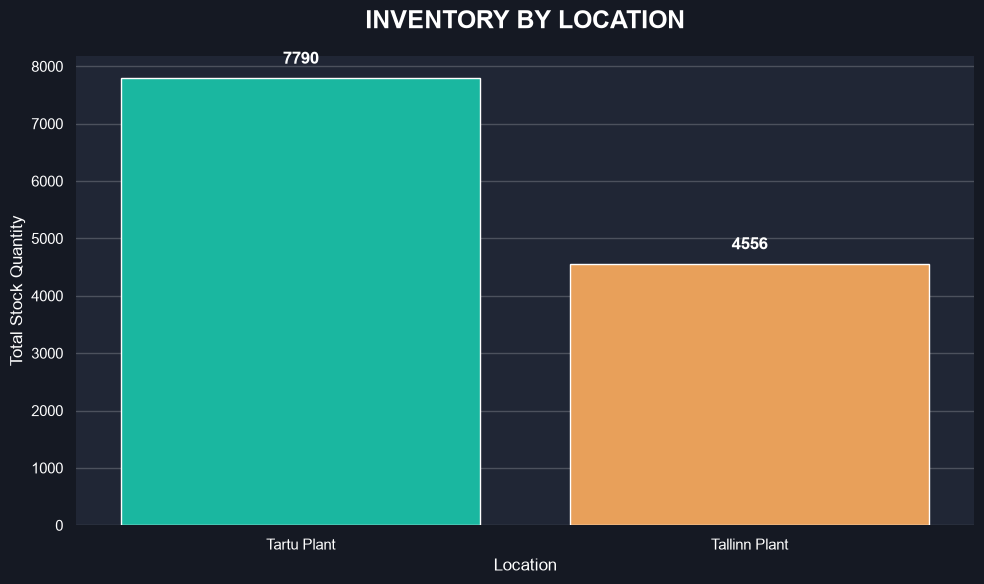

In [42]:

location_stock = (
    df.groupby("Plant_Location", as_index=False)["Stock_Qty"]
    .sum()
    .sort_values("Stock_Qty", ascending=False)
)


sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 6), facecolor="#151923")
ax = sns.barplot(
    data=location_stock,
    x="Plant_Location",
    y="Stock_Qty",
    hue="Plant_Location",
    palette=["#00D1B2", "#FF9F43"],
    legend=False
)

ax.set_facecolor("#202635")
ax.set_title(
    "INVENTORY BY LOCATION",
    fontsize=18,
    fontweight="bold",
    color="white",
    pad=20
)
ax.set_xlabel("Location", color="white", fontsize=12)
ax.set_ylabel("Total Stock Quantity", color="white", fontsize=12)

ax.tick_params(colors="white")
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)


for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=8,
        color="white",
        fontsize=12,
        fontweight="bold"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.savefig(
    "../images/inventory_by_location.png",
)

plt.show()

### 11.Top 5 Materials by Stock Quantity

In this section, we identify the five materials with the highest total stock quantities. We group the data by `Material_ID`, calculate the total stock for each material, and sort the results in descending order. This helps identify which materials have the largest inventory levels.

In [43]:

top_5_stock = (
    df.groupby("Material_ID", as_index=False)["Stock_Qty"]
    .sum()
    .sort_values("Stock_Qty", ascending=False)
    .head(5)
)

top_5_stock

,Material_ID,Stock_Qty
1,SAP-2204,3294
2,SAP-4051,2745
3,SAP-8831,2546
4,SAP-9941,2172
0,SAP-1092,1589


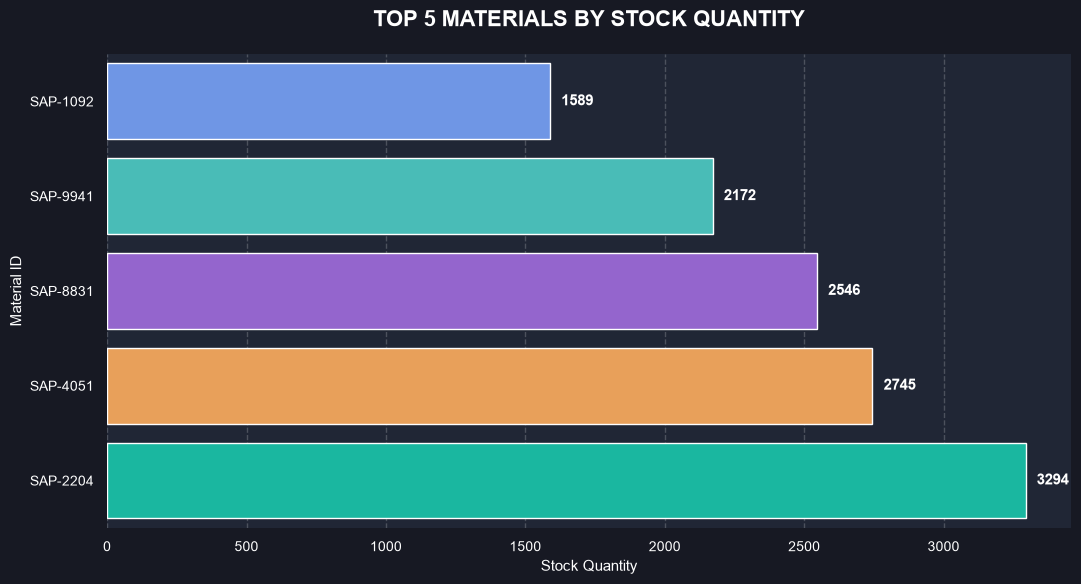

In [44]:

sns.set_theme(style="darkgrid")

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor("#171923")
ax.set_facecolor("#202635")


plot_data = top_5_stock.sort_values("Stock_Qty", ascending=True)


colors = ["#5B8FF9", "#36CFC9", "#9254DE", "#FF9F43", "#00D1B2"]

sns.barplot(
    data=plot_data,
    x="Stock_Qty",
    y="Material_ID",
    hue="Material_ID",
    palette=colors,
    legend=False,
    ax=ax
)


ax.set_title(
    "TOP 5 MATERIALS BY STOCK QUANTITY",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=20
)
ax.set_xlabel("Stock Quantity", color="white", fontsize=11)
ax.set_ylabel("Material ID", color="white", fontsize=11)

ax.tick_params(colors="white", labelsize=10)
ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.grid(axis="y", visible=False)


for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=8,
        color="white",
        fontsize=11,
        fontweight="bold"
    )

# Remove unnecessary borders
sns.despine(left=True, bottom=True)

plt.tight_layout()


plt.savefig(
    "../images/top_5_materials_by_stock.png",
    
)

plt.show()


### 12.Stock Distribution by Location

This section visualizes the percentage distribution of total inventory between Tallinn Plant and Tartu Plant using a pie chart. The chart helps compare each location's share of the total stock and identify where most of the inventory is held.

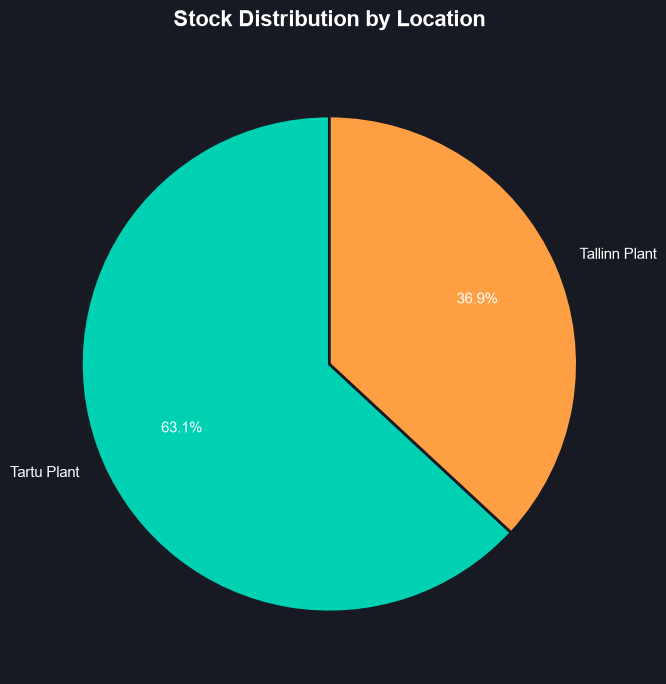

In [45]:


location_stock = (
    df.groupby("Plant_Location")["Stock_Qty"]
    .sum()
    .sort_values(ascending=False)
)

stock_percentages = (
    location_stock / location_stock.sum() * 100
)


# Set up the chart
fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor("#171923")
ax.set_facecolor("#171923")

colors = ["#00D1B2", "#FF9F43"]

# Create the pie chart
ax.pie(
    stock_percentages,
    labels=stock_percentages.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    textprops={"color": "white", "fontsize": 11},
    wedgeprops={"edgecolor": "#171923", "linewidth": 2},
    pctdistance=0.65
)

ax.set_title(
    "Stock Distribution by Location",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=20
)

# Save the chart
plt.tight_layout()
plt.savefig(
    "../images/stock_distribution_by_location.png",
    
)

plt.show()


### 13.Monthly Stock Trend by Location

In this section, we analyze how recorded stock quantities change over time at Tallinn Plant and Tartu Plant. We aggregate stock quantities by month and location, then visualize the results using a line chart.

The chart helps compare monthly patterns between the two locations and identify periods with higher or lower recorded quantities. These values represent the sum of stock quantities recorded in the dataset for each month, not necessarily the actual month-end inventory balance or sales volume.

In [46]:

print("Date range:")
print(df["Posting_Date"].min(), "—", df["Posting_Date"].max())

print("\nRecords per month:")
print(
    df.groupby(df["Posting_Date"].dt.to_period("M"))
      .size()
)

Date range:
2026-01-07 00:00:00 — 2026-07-20 00:00:00

Records per month:
Posting_Date
2026-01    14
2026-02    11
2026-03    15
2026-04    19
2026-05     9
2026-06    15
2026-07    10
Freq: M, dtype: int64


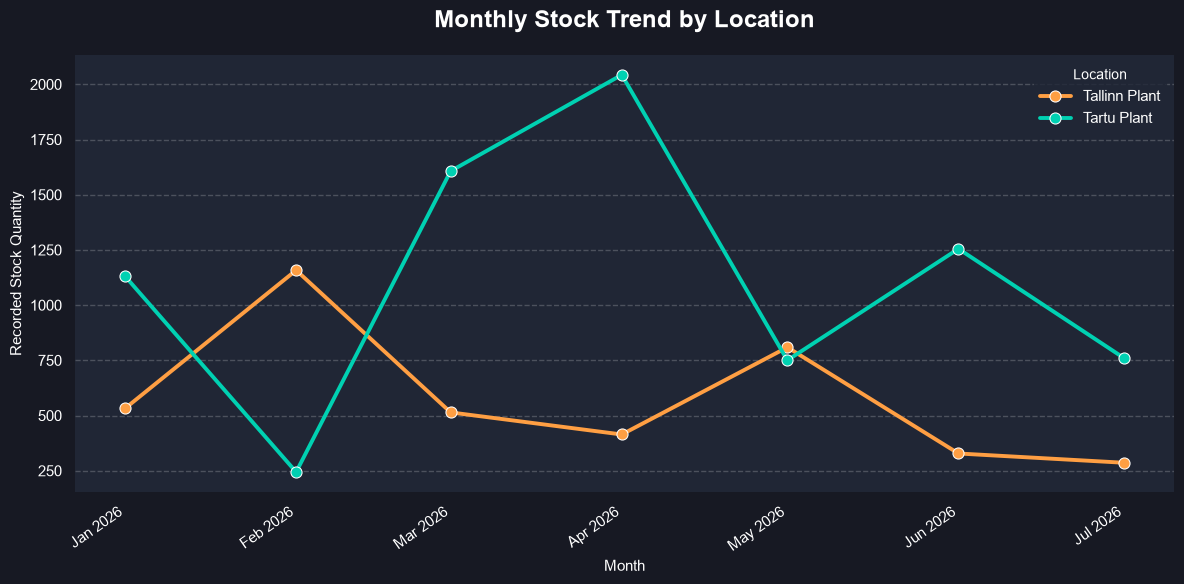

In [49]:

monthly_stock = (
    df.groupby([
        pd.Grouper(key="Posting_Date", freq="MS"),
        "Plant_Location"
    ])["Stock_Qty"]
    .sum()
    .reset_index()
)


sns.set_theme(style="darkgrid")

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor("#171923")
ax.set_facecolor("#202635")


palette = {
    "Tallinn Plant": "#FF9F43",
    "Tartu Plant": "#00D1B2"
}


sns.lineplot(
    data=monthly_stock,
    x="Posting_Date",
    y="Stock_Qty",
    hue="Plant_Location",
    hue_order=["Tallinn Plant", "Tartu Plant"],
    palette=palette,
    marker="o",
    markersize=8,
    linewidth=2.8,
    ax=ax
)

ax.set_title(
    "Monthly Stock Trend by Location",
    fontsize=17,
    fontweight="bold",
    color="white",
    pad=20
)

ax.set_xlabel("Month", color="white", fontsize=11)
ax.set_ylabel("Recorded Stock Quantity", color="white", fontsize=11)


ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=35, ha="right", color="white")
ax.tick_params(axis="y", colors="white")


legend = ax.legend(
    title="Location",
    facecolor="#202635",
    edgecolor="#202635",
    labelcolor="white",
    title_fontsize=10
)
legend.get_title().set_color("white")


ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.grid(axis="x", visible=False)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()


plt.savefig(
    "../images/monthly_stock_trend_by_location.png",
   
)

plt.show()


### 14.Exporting the Cleaned Dataset

After completing the data cleaning and inventory analysis, we export the cleaned dataset into three common formats: CSV, JSON, and Excel. This makes the data easier to reuse in other applications, share with stakeholders, and use for further analysis.

In [51]:
# Save as CSV
df.to_csv("../output/cleaned_sap_inventory.csv", index=False)

# Save as JSON
df.to_json(
    "../output/cleaned_sap_inventory.json",
    orient="records",
    indent=4,
    date_format="iso"
)

# Save as Excel
df.to_excel("../output/cleaned_sap_inventory.xlsx", index=False)


## Conclusion

### Project Summary

In this project, we cleaned and analyzed synthetic SAP inventory data from two locations: Tallinn Plant and Tartu Plant. The main goal was to improve data quality, standardize the dataset, and explore inventory distribution using Python.

### Key Steps Completed

- **Data Integration:** Combined two inventory datasets into a single DataFrame.
- **Data Cleaning:** Removed fully empty rows, checked for duplicate records, standardized material categories and plant locations, and cleaned stock quantity values.
- **Date Standardization:** Converted inconsistent date formats into a consistent datetime format.
- **Inventory Analysis:** Identified the top 5 materials by total stock quantity and compared inventory levels between the two locations.
- **Data Visualization:** Created charts showing inventory distribution by location and monthly stock quantity trends.
- **Data Export:** Saved the cleaned dataset in CSV, JSON, and Excel formats for reuse and further analysis.

### Key Findings

- Tartu Plant recorded a higher total stock quantity than Tallinn Plant in the analyzed dataset.
- Tartu Plant accounted for approximately **63.1%** of the total recorded stock quantity, while Tallinn Plant accounted for **36.9%**.
- **25 records** had a stock quantity of zero. Within this project, zero stock was treated as an unavailable item.
- The top 5 materials were identified based on their aggregated stock quantities.
- Monthly stock quantity trends were visualized for both locations to support comparison over time.

### Tools and Skills

**Python · Pandas · NumPy · Matplotlib · Seaborn · Data Cleaning · Exploratory Data Analysis (EDA) · Data Visualization · Data Export**

### Final Note

This project demonstrates a basic data analytics workflow, from raw data preparation and quality checks to exploratory analysis, visualization, and exporting cleaned data. Since the dataset is synthetic, the findings illustrate the analytical process rather than the actual operational performance of a real SAP inventory system.